In [34]:
import pandas as pd
import numpy as np
import seaborn as sns
import scipy.stats as stats
import statsmodels.api as sm
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from typing import Any, Callable
import yfinance as yf

from copulas.multivariate import GaussianMultivariate, Multivariate
from copulas.univariate import GaussianUnivariate, StudentTUnivariate, GammaUnivariate

import sklearn.decomposition as skd
from factor_analyzer import FactorAnalyzer

# Obtaining Prices for Analysis

In [35]:
# Stock and FX Data
start_date = '2010-01-01'
end_date = '2024-01-01'
stocks = ['AAPL', 'ASML.AS', 'AIR.PA', 'MC.PA', 'SC0D.DE']
stock_data = yf.download(' '.join(stocks), start=start_date, end=end_date)
# Combine data
data = pd.DataFrame(stock_data['Adj Close'].values, columns = stock_data['Adj Close'].columns, index = stock_data.index)

[*********************100%%**********************]  5 of 5 completed


In [36]:
data.head()

Ticker,AAPL,AIR.PA,ASML.AS,MC.PA,SC0D.DE
Date,,,,,
2010-01-04,6.461977,11.523581,27.279852,59.936466,47.728802
2010-01-05,6.473149,11.486513,27.330450,59.654682,47.642601
2010-01-06,6.370185,11.589476,27.622820,60.233471,47.599602
2010-01-07,6.358408,11.704797,27.116798,60.918900,47.562500
2010-01-08,6.400680,11.820115,26.205975,61.741425,47.728401


In [37]:
# Make names more readable
data = data.rename(columns={'ASML.AS': 'ASML', 'AIR.PA': 'AIRBUS', 'MC.PA': 'LVMH', 'SC0D.DE': 'EURO50'})
# Getting Daily Log Returns
returns = data.apply(np.log).diff(1)
# Filling non-trading days with zero returns
returns = returns.fillna(0)

In [38]:
returns

Ticker,AAPL,AIRBUS,ASML,LVMH,EURO50
Date,,,,,
2010-01-04,0.000000,0.000000,0.000000,0.000000,0.000000
2010-01-05,0.001728,-0.003222,0.001853,-0.004712,-0.001808
2010-01-06,-0.016034,0.008924,0.010641,0.009656,-0.000903
2010-01-07,-0.001851,0.009901,-0.018489,0.011315,-0.000780
2010-01-08,0.006626,0.009804,-0.034166,0.013412,0.003482
...,...,...,...,...,...
2023-12-22,-0.005563,0.006620,0.001464,-0.007697,-0.001098
2023-12-26,-0.002845,0.000000,0.000000,0.000000,0.000000
2023-12-27,0.000518,0.000000,0.000000,0.000000,0.000000


## Analysis of Returns

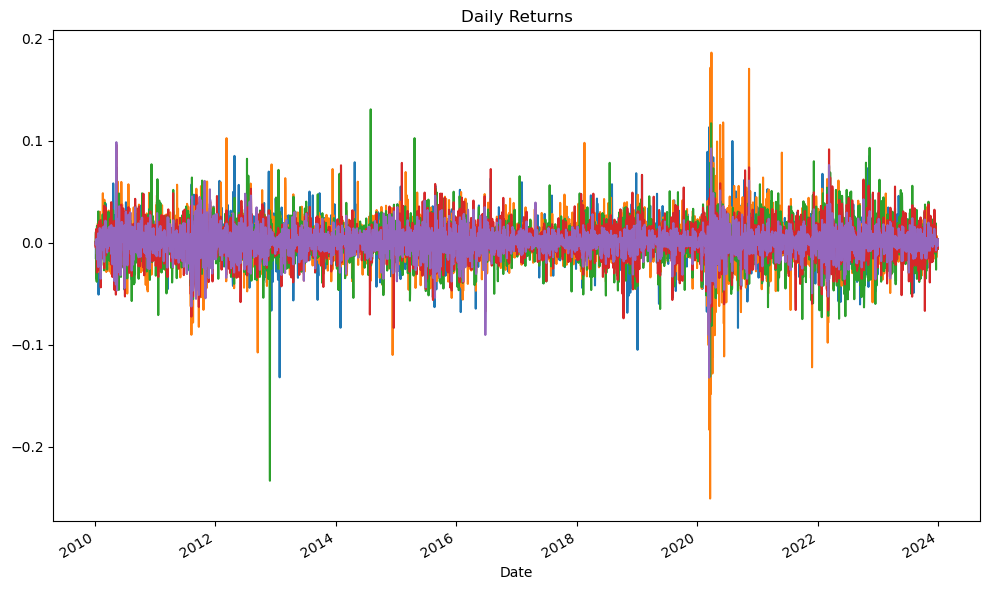

In [39]:
returns.plot(legend=0, figsize=(10,6), title='Daily Returns')
plt.tight_layout()

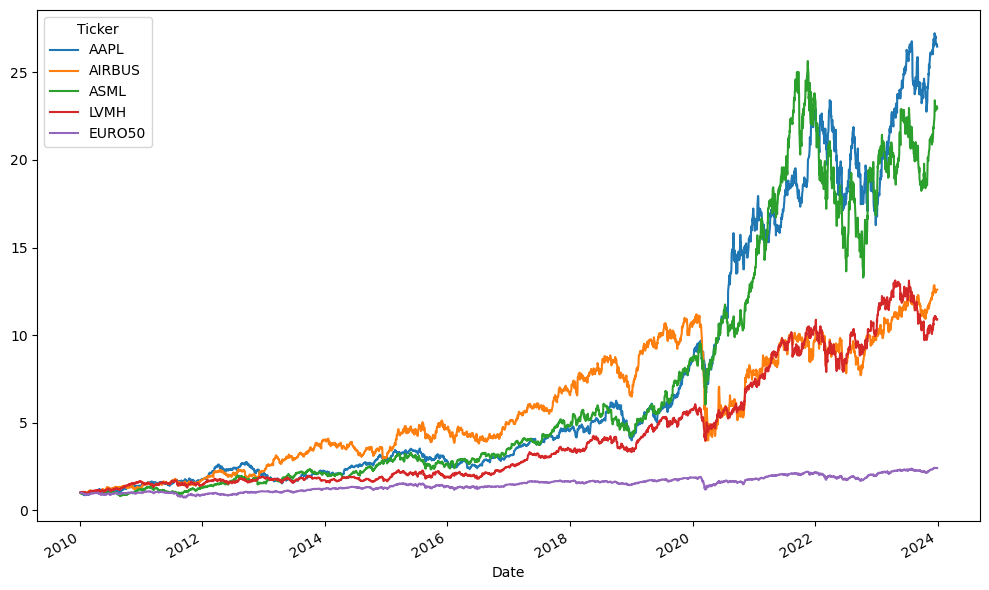

In [40]:
returns.cumsum().apply(np.exp).plot(legend=1, figsize=(10,6))
plt.tight_layout()

## Analysis of Correlation

As can be seen from the plot our portfolios are correlated and some of the assets have severe correlations. To expand on these correlations we should use copula to analyze behavior of returns better.

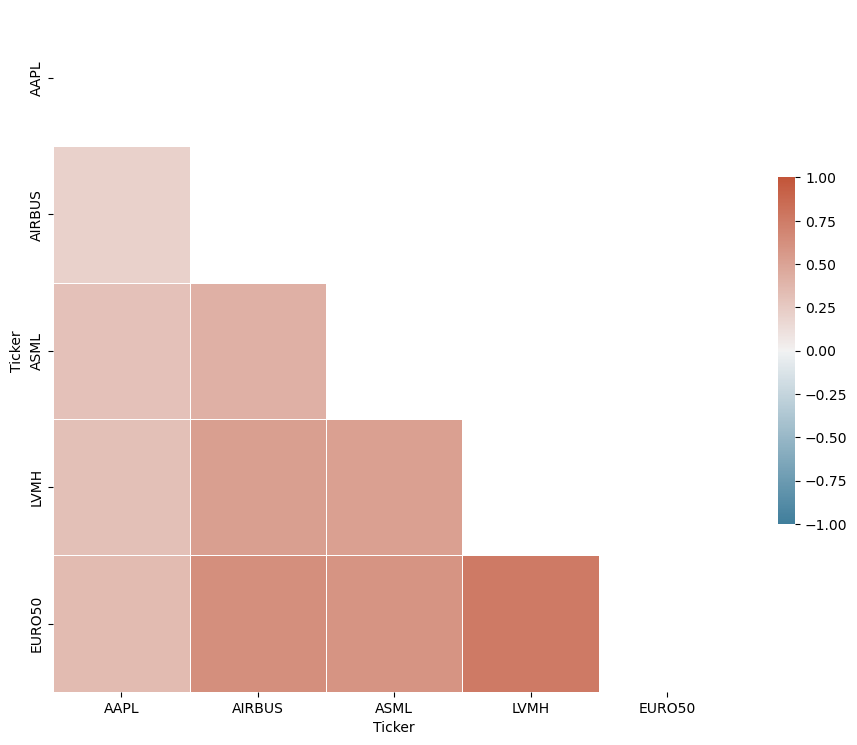

In [41]:
# calculate the correlation matrix to measure the linear relationships between the variables:
corr_matrix = returns.corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))   # Create a mask for the upper triangle of the correlation matrix.

# Visualizing:
f, ax = plt.subplots(figsize=(11, 9))
cmap = sns.diverging_palette(230, 20, as_cmap=True)     # Setting Colors
sns.heatmap(corr_matrix, mask=mask, cmap=cmap, vmax=1, vmin=-1, center=0,
            square=True, linewidths=.5, cbar_kws={"shrink": .5})
plt.show()

# Copulas

In [42]:
from copulas.bivariate import Gumbel, Clayton, Frank
from copulas.bivariate import Bivariate 
from copulas.multivariate import Multivariate
from scipy.stats import rankdata

In [43]:
pairs = [(a, b) for idx, a in enumerate(returns.columns) for b in returns.columns[idx + 1:]]

# Function to transform data to uniform [0, 1] using empirical CDF
def to_uniform(data):
    return (rankdata(data) - 0.5) / len(data)

## Bivariate - Archimedean

In [45]:
import warnings
warnings.filterwarnings(action = 'ignore')
def AIC(model, data): return 2 - 2 * np.sum(model.log_probability_density(data))

for idx, pair in enumerate(pairs):
    for i, model in enumerate([Clayton, Frank, Gumbel]):
    
        print()
        print(model.__name__)
        print(pair)
        copula_data = returns[list(pair)].to_numpy()        # We choose them because they have the highest correlation
        # Transform data to uniform
        uniform_data = np.column_stack((to_uniform(copula_data[:, 0]), to_uniform(copula_data[:, 1])))
        _ = model()
        _.fit(uniform_data)
        print(f"Fitted Theta: {_.theta}")
        print(f"Fitted Tau: {_.tau}")
        print(f"Log likelihood: {np.sum(np.log(_.partial_derivative(uniform_data)))}")
        print(f"AIC: {AIC(_, uniform_data)}")

for idx, pair in enumerate(pairs):
    for i, model in enumerate([GaussianUnivariate, StudentTUnivariate]):
    
           
        print()
        print(model.__name__)
        print(pair)
        copula_data = returns[list(pair)].to_numpy()        # We choose them because they have the highest correlation
        # Transform data to uniform
        uniform_data = np.column_stack((to_uniform(copula_data[:, 0]), to_uniform(copula_data[:, 1])))
        cop = GaussianMultivariate(distribution={
            pair[0]: model,
            pair[1]: model
        })

        cop.fit(uniform_data) 
        print(f"Fitted Theta: {_.theta}")
        print(f"Fitted Tau: {cop.to_dict()['correlation'][0][1]}")
        print(f"Log likelihood: {np.sum(cop.log_probability_density(uniform_data)) / 3}")
        print(f"AIC: {AIC(_, uniform_data)}")



Clayton
('AAPL', 'AIRBUS')
Fitted Theta: 0.28535323007070207
Fitted Tau: 0.12486176155004015
Log likelihood: -3622.8650683150254
AIC: -192.7038143379417

Frank
('AAPL', 'AIRBUS')
Fitted Theta: 1.1381871535273458
Fitted Tau: 0.12486176155004015
Log likelihood: -3616.2198133501433
AIC: -127.00394479406452

Gumbel
('AAPL', 'AIRBUS')
Fitted Theta: 1.1426766150353511
Fitted Tau: 0.12486176155004015
Log likelihood: -3611.2848851836584
AIC: -134.78173698745002

Clayton
('AAPL', 'ASML')
Fitted Theta: 0.5255911556135506
Fitted Tau: 0.20810619107741807
Log likelihood: -3690.5918973911403
AIC: -362.37661523917023

Frank
('AAPL', 'ASML')
Fitted Theta: 1.9417982527674897
Fitted Tau: 0.20810619107741807
Log likelihood: -3616.171126432573
AIC: -358.35739902094224

Gumbel
('AAPL', 'ASML')
Fitted Theta: 1.2627955778067752
Fitted Tau: 0.20810619107741807
Log likelihood: -3616.2713482650192
AIC: -352.59105129937905

Clayton
('AAPL', 'LVMH')
Fitted Theta: 0.45549361376144976
Fitted Tau: 0.185499816089401

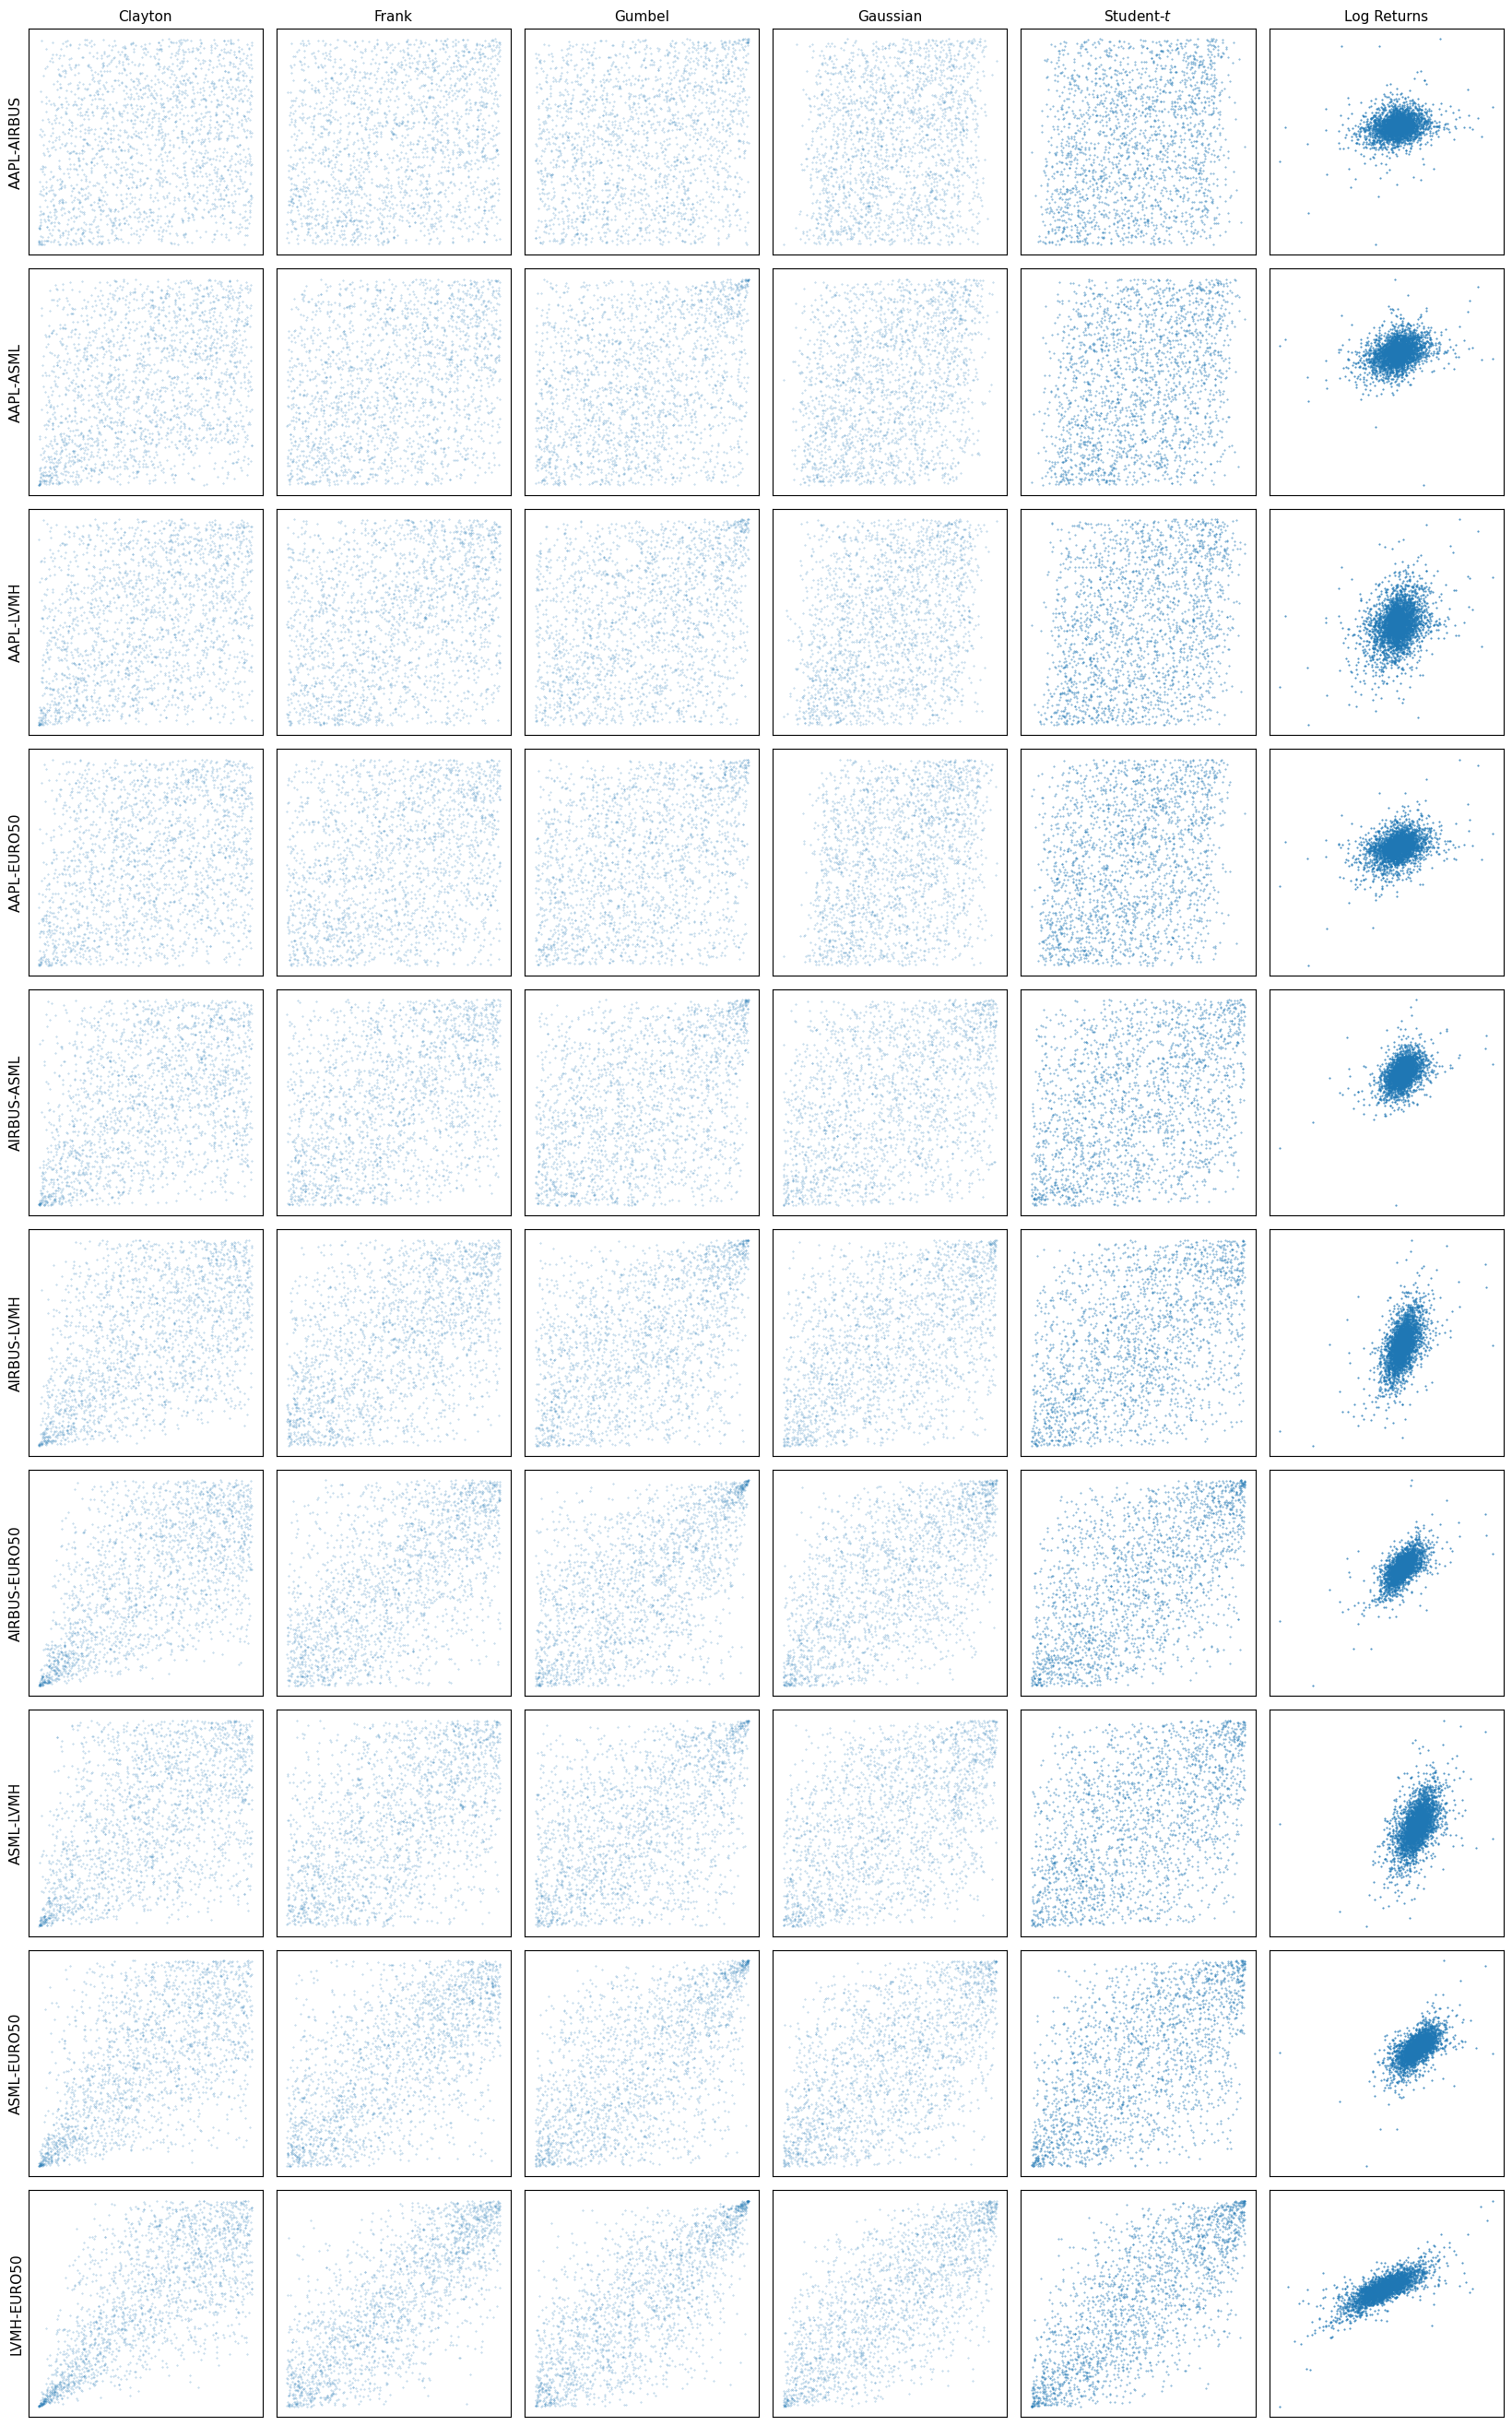

In [46]:
fig, axs = plt.subplots(10, 6, figsize = (2*8.2543, 3.2*8.2543))

# Choosing pair of data
for i, model in enumerate([Clayton, Frank, Gumbel]):
    for idx, (pair, ax) in enumerate(zip(pairs, axs[:, i].flatten())):
        copula_data = returns[list(pair)].to_numpy()        # We choose them because they have the highest correlation
        # Transform data to uniform
        uniform_data = np.column_stack((to_uniform(copula_data[:, 0]), to_uniform(copula_data[:, 1])))
        _ = model()
        _.fit(uniform_data)
        synthetic_data = _.sample(2_000)
        synthetic_data = pd.DataFrame(list(map(np.ravel, synthetic_data)))
        synthetic_data.columns = ['X', 'Y']
        ax.scatter(x=synthetic_data['X'], y=synthetic_data['Y'], s = .1, alpha = .5)
        if i == 0: ax.set_ylabel(pair[0] + '-' + pair[1], fontsize = 11)
        if idx == 0: ax.set_title(model.__name__, fontsize = 11)

for idx, (pair, ax) in enumerate(zip(pairs, axs[:, 3].flatten())):
    copula_data = returns[list(pair)].to_numpy()        # We choose them because they have the highest correlation
    # Transform data to uniform
    
    uniform_data = np.column_stack((to_uniform(copula_data[:, 0]), to_uniform(copula_data[:, 1])))
    
    model = GaussianMultivariate(distribution={pair[0]: GaussianUnivariate,pair[1]: GaussianUnivariate})
    model.fit(uniform_data)
    synthetic_data = model.sample(2_000)
    synthetic_data.columns = ['X', 'Y']
    ax.scatter(x=synthetic_data['X'], y=synthetic_data['Y'], s = .1, alpha = .5)
    if idx == 0: ax.set_title('Gaussian', fontsize = 11)

for idx, (pair, ax) in enumerate(zip(pairs, axs[:, 4].flatten())):
    copula_data = returns[list(pair)].to_numpy()        # We choose them because they have the highest correlation
    # Transform data to uniform
    
    uniform_data = np.column_stack((to_uniform(copula_data[:, 0]), to_uniform(copula_data[:, 1])))
    
    model = GaussianMultivariate(distribution={pair[0]: StudentTUnivariate,pair[1]: StudentTUnivariate})
    model.fit(uniform_data)
    synthetic_data = model.sample(2_000)
    synthetic_data.columns = ['X', 'Y']
    ax.scatter(x=synthetic_data['X'], y=synthetic_data['Y'], s = .15, alpha = .75)
    if idx == 0: ax.set_title('Student-$t$', fontsize = 11)

for idx, (pair, ax) in enumerate(zip(pairs, axs[:, 5].flatten())):
    copula_data = returns[list(pair)].to_numpy()        # We choose them because they have the highest correlation
    # Transform data to uniform
    
    norm_data = np.column_stack(((copula_data[:, 0]), (copula_data[:, 1])))
    ax.scatter(x=norm_data[:, 0], y=norm_data[:, 1], s = .25, alpha = .9)    

    if idx == 0: ax.set_title('Log Returns', fontsize = 11)

plt.setp(plt.gcf().get_axes(), xticks=[], yticks=[])
fig.tight_layout()
# plt.savefig('copula_fitted.pdf', bbox_inches = 'tight')
plt.show()

## Multivariate

In [27]:
multidim_t_Student_copula = GaussianMultivariate(distribution={
    "AAPL": StudentTUnivariate,
    "AIRBUS": StudentTUnivariate,
    "ASML": StudentTUnivariate,
    "LVMH": StudentTUnivariate,
    "EURO50": StudentTUnivariate
})

multidim_copula_df = returns[['AAPL', 'AIRBUS', 'ASML', 'LVMH', 'EURO50']]        # This type of copula takes dataframe as input
multidim_t_Student_copula.fit(multidim_copula_df)            # Here we fit raw data, as it transforms them into the uniform automatically

student_parameters = multidim_t_Student_copula.to_dict()

print("\nCorrelations between variables: \n", student_parameters['correlation'])
print("Optimal fitted t-Student distributions for each parameter: \n", student_parameters['univariates'])

# Generate synthetic data
synthetic_data = multidim_t_Student_copula.sample(25_000)

print(synthetic_data)       # Not sure what else can be done with the 5D data


Correlations between variables: 
 [[1.0, 0.2003806995156653, 0.3224270818313941, 0.3016710791167937, 0.3249305284078113], [0.2003806995156653, 1.0, 0.42645539734231835, 0.5283644272823733, 0.6294951946522722], [0.3224270818313941, 0.42645539734231835, 1.0, 0.5363884157933941, 0.6237070227088277], [0.3016710791167937, 0.5283644272823733, 0.5363884157933941, 1.0, 0.7552468758457708], [0.3249305284078113, 0.6294951946522722, 0.6237070227088277, 0.7552468758457708, 1.0]]
Optimal fitted t-Student distributions for each parameter: 
 [{'df': 3.1236418618801176, 'loc': 0.0010851783713737464, 'scale': 0.011204369510174002, 'type': 'copulas.univariate.student_t.StudentTUnivariate'}, {'df': 3.2162612675389086, 'loc': 0.0006323093546036936, 'scale': 0.013491814773996597, 'type': 'copulas.univariate.student_t.StudentTUnivariate'}, {'df': 4.1086744765835945, 'loc': 0.0010581137098243116, 'scale': 0.014181330591677541, 'type': 'copulas.univariate.student_t.StudentTUnivariate'}, {'df': 3.902203972417

In [28]:
multidim_gauss_copula = GaussianMultivariate(distribution={
    "AAPL": GaussianUnivariate,
    "AIRBUS": GaussianUnivariate,
    "ASML": GaussianUnivariate,
    "LVMH": GaussianUnivariate,
    "EURO50": GaussianUnivariate
})

multidim_copula_df = returns[['AAPL', 'AIRBUS', 'ASML', 'LVMH', 'EURO50']]        # This type of copula takes dataframe as input
multidim_gauss_copula.fit(multidim_copula_df)            # Here we fit raw data, as it transforms them into the uniform automatically

gauss_parameters = multidim_gauss_copula.to_dict()

print("\nCorrelations between variables: \n", gauss_parameters['correlation'])
print("Optimal fitted t-Student distributions for each parameter: \n", gauss_parameters['univariates'])

# Generate synthetic data
synthetic_data = multidim_gauss_copula.sample(25_000)

print(synthetic_data)       # Not sure what else can be done with the 5D data


Correlations between variables: 
 [[1.0, 0.2080943009739426, 0.3204513546037266, 0.31799298525499675, 0.3372905279911678], [0.2080943009739426, 1.0, 0.41697510409001654, 0.5301763376428602, 0.6345529451749178], [0.3204513546037266, 0.41697510409001654, 1.0, 0.5306763957594226, 0.6112792914651652], [0.31799298525499675, 0.5301763376428602, 0.5306763957594226, 1.0, 0.759177268636644], [0.3372905279911678, 0.6345529451749178, 0.6112792914651652, 0.759177268636644, 1.0]]
Optimal fitted t-Student distributions for each parameter: 
 [{'loc': 0.0009057055059125005, 'scale': 0.017313090092073852, 'type': 'copulas.univariate.gaussian.GaussianUnivariate'}, {'loc': 0.0007003223709510333, 'scale': 0.02140609965254873, 'type': 'copulas.univariate.gaussian.GaussianUnivariate'}, {'loc': 0.0008659703545809421, 'scale': 0.01956251577421527, 'type': 'copulas.univariate.gaussian.GaussianUnivariate'}, {'loc': 0.0006604350751384373, 'scale': 0.0168875737611181, 'type': 'copulas.univariate.gaussian.Gaussia

In [29]:
np.sum(multidim_gauss_copula.log_probability_density(multidim_copula_df)) / 7.5

-2880.3146849960294

In [30]:
np.sum(multidim_t_Student_copula.log_probability_density(multidim_copula_df)) / 7.5

-2935.469034583949

# Factor Analysis

## Extending portfolio

In [101]:
# Stock and FX Data
start_date = '2010-01-01'
end_date = '2024-01-01'
stocks = ['SC0D.DE', 'ASML.AS', 'AIR.PA', 'SPY', 'AAPL', 'GM', 'DAL', '0700.HK', 'CL=F', 'GC=F']
stock_data = yf.download(' '.join(stocks), start=start_date, end=end_date)
# Combine data
data = pd.DataFrame(stock_data['Adj Close'].values, columns = stock_data['Adj Close'].columns, index = stock_data.index)

[*********************100%%**********************]  10 of 10 completed


In [102]:
# Make names more readable
data = data.rename(columns={'ASML.AS': 'ASML', 'AIR.PA': 'AIRBUS', 'SPY': 'SNP500', 'SC0D.DE': 'EURO50', 'NVO': 'NOVO', 'DAL': 'DELTA', '0700.HK': 'TENCENT', 'CL=F': 'OIL', 'GC=F': 'GOLD'})
# Getting Daily Log Returns
returns = data.apply(np.log).diff(1)
# Filling non-trading days with zero returns
returns = returns.fillna(0)

In [103]:
# Theoretical Categories:
# EU: EURO50, AIRBUS, ASML
# US: SNP500, AAPL, GM, DELTA
# Industry: AIRBUS, GM, ASML
# Aerospace: AIRBUS, DELTA
# Tech: AAPL, TENCENT, ASML
# Gold should not correlate with anyone, while Oil should correlate with all

returns

Ticker,TENCENT,AAPL,AIRBUS,ASML,OIL,DELTA,GOLD,GM,EURO50,SNP500
Date,,,,,,,,,,
2010-01-04,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2010-01-05,0.022367,0.001728,-0.003222,0.001853,0.003185,0.075508,0.000358,0.000000,-0.001808,0.002643
2010-01-06,0.002325,-0.016034,0.008924,0.010641,0.017097,0.000826,0.015795,0.000000,-0.000903,0.000704
2010-01-07,-0.039081,-0.001851,0.009901,-0.018489,-0.006271,0.046783,-0.002468,0.000000,-0.000780,0.004212
2010-01-08,0.013793,0.006626,0.009804,-0.034166,0.001088,-0.017488,0.004491,0.000000,0.003482,0.003322
...,...,...,...,...,...,...,...,...,...,...
2023-12-22,-0.131796,-0.005563,0.006620,0.001464,-0.004476,0.000243,0.008789,-0.006365,-0.001098,0.002008
2023-12-26,0.000000,-0.002845,0.000000,0.000000,0.026958,-0.009037,0.000535,0.003049,0.000000,0.004214
2023-12-27,0.000000,0.000518,0.000000,0.000000,-0.019509,-0.004179,0.011449,-0.001385,0.000000,0.001806


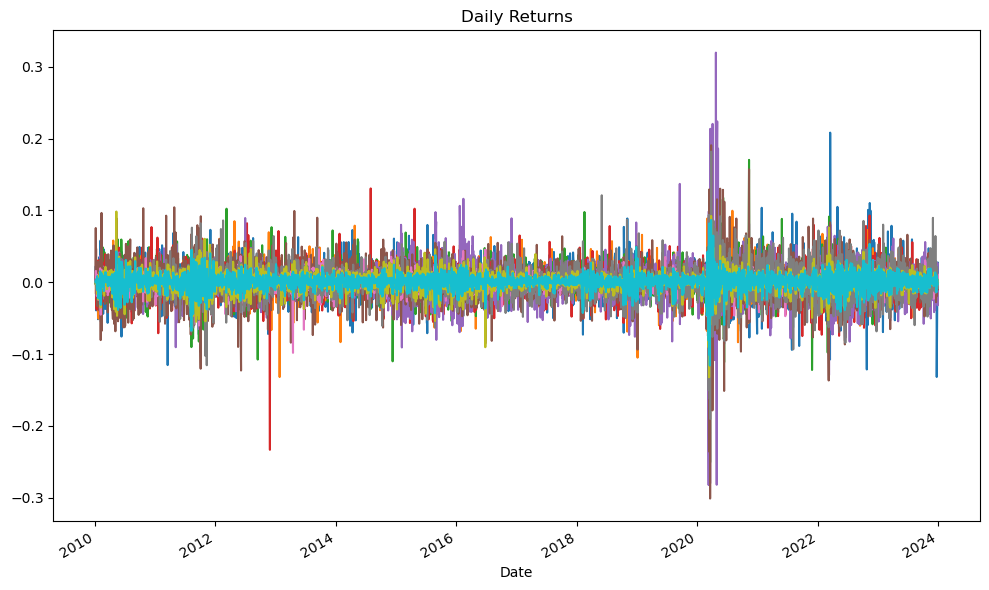

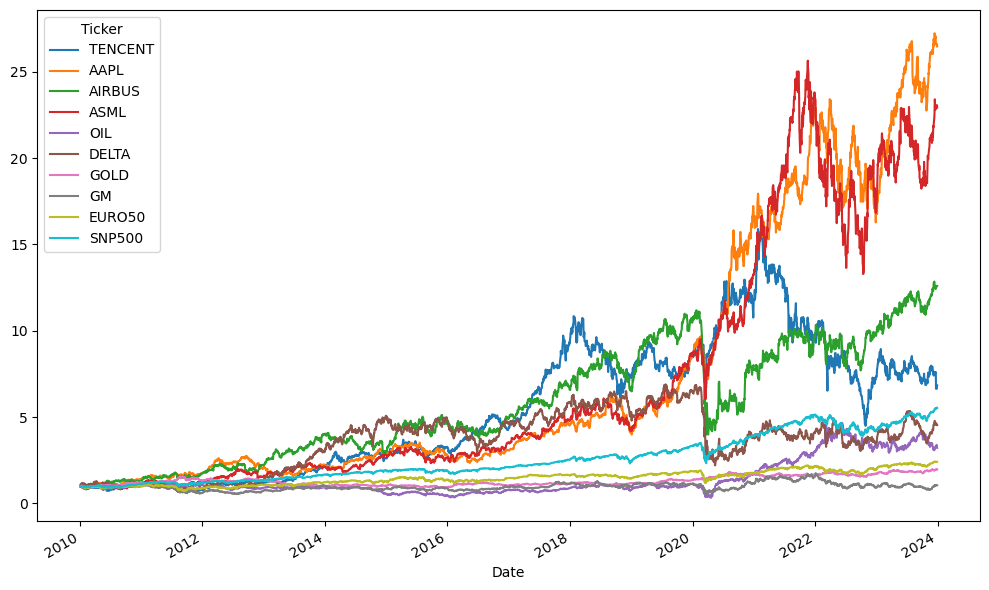

In [104]:
returns.plot(legend=0, figsize=(10,6), title='Daily Returns')
plt.tight_layout()

returns.cumsum().apply(np.exp).plot(legend=1, figsize=(10,6))
plt.tight_layout()

# calculate the correlation matrix to measure the linear relationships between the variables:
corr_matrix = returns.corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))   # Create a mask for the upper triangle of the correlation matrix.

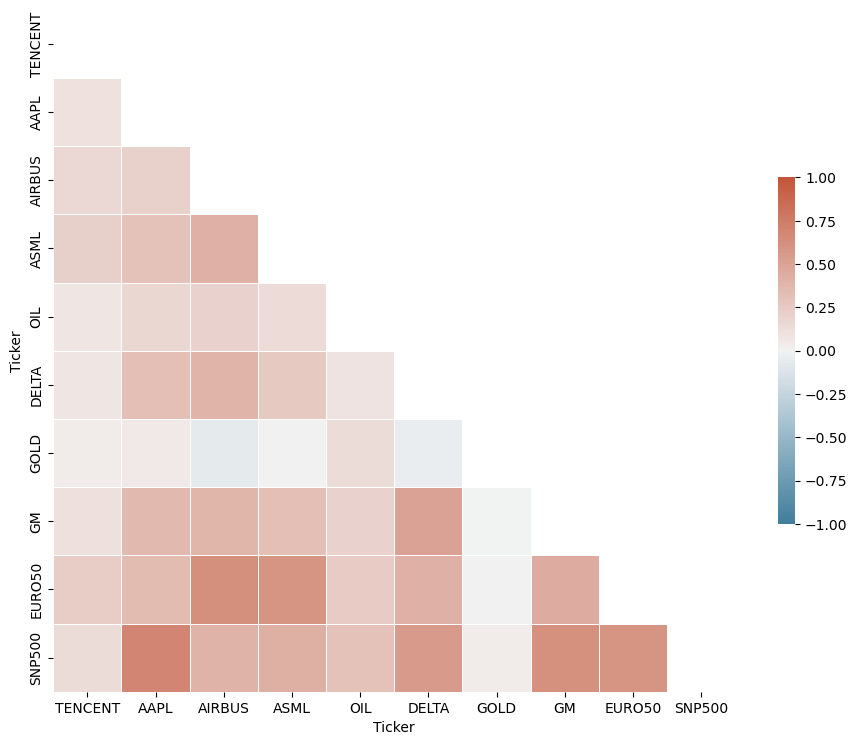

In [105]:
# Visualizing:
f, ax = plt.subplots(figsize=(11, 9))
cmap = sns.diverging_palette(230, 20, as_cmap=True)     # Setting Colors
sns.heatmap(corr_matrix, mask=mask, cmap=cmap, vmax=1, vmin=-1, center=0,
            square=True, linewidths=.5, cbar_kws={"shrink": .5})
plt.show()

## PCA

### Calibrating

In [106]:
n = 10
pca = skd.PCA(n_components=n)
df_pca = pca.fit_transform(returns)

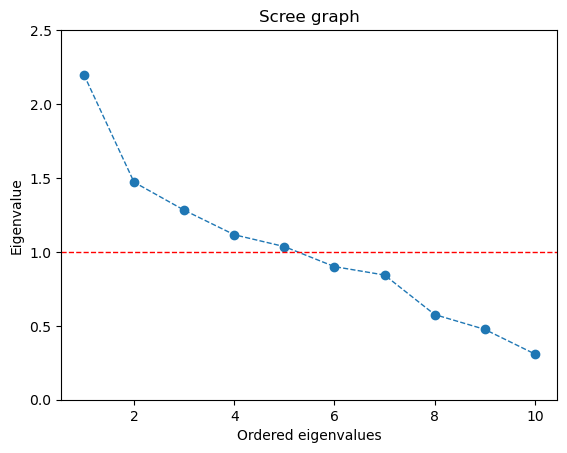

In [107]:
plt.plot(range(1, len(pca.explained_variance_) + 1), pca.singular_values_, ls = 'dashed', lw = 1)
plt.scatter(range(1, len(pca.explained_variance_) + 1), pca.singular_values_, marker = 'o')
plt.axhline(1, c = 'red', ls = 'dashed', lw = 1)
plt.ylim([0,2.5])
plt.title("Scree graph")
plt.ylabel('Eigenvalue')
plt.xlabel('Ordered eigenvalues')
plt.show()

### Running PCA

In [108]:
# Lowering dimensions according to Scree Graph
n = 5
pca = skd.PCA(n_components=n)
df_pca = pca.fit_transform(returns)

In [109]:
loadings = pca.components_.T
loadings_column = [f'PC{i}' for i in range(n)]
df_loadings = pd.DataFrame(loadings, columns=loadings_column, index=returns.columns)

[Text(0, 0.5, 'PC0'),
 Text(0, 1.5, 'PC1'),
 Text(0, 2.5, 'PC2'),
 Text(0, 3.5, 'PC3'),
 Text(0, 4.5, 'PC4')]

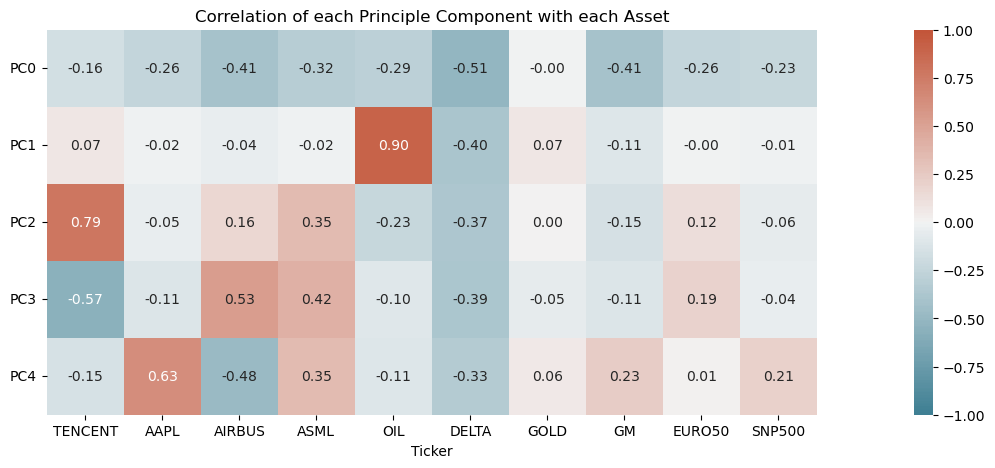

In [110]:
plt.figure(figsize=(25,5))
plt.title("Correlation of each Principle Component with each Asset")

# plot the heatmap for correlation matrix
ax = sns.heatmap(df_loadings.T, 
                 vmin=-1, vmax=1, center=0,
                 cmap=sns.diverging_palette(220, 20, n=200),
                 square=True, annot=True, fmt='.2f')

ax.set_yticklabels(
    ax.get_yticklabels(),
    rotation=0)

## Factor Analysis

In [111]:
fa = FactorAnalyzer(n, rotation=None)
fa.fit(returns)

FactorAnalyzer(n_factors=5, rotation=None, rotation_kwargs={})

In [112]:
fa_loadings = fa.loadings_
fa_loadings_column = [f'FA{i}' for i in range(1, n + 1)]
df_loadings_fa = pd.DataFrame(fa_loadings, columns=fa_loadings_column, index=returns.columns)

[Text(0, 0.5, 'FA1'),
 Text(0, 1.5, 'FA2'),
 Text(0, 2.5, 'FA3'),
 Text(0, 3.5, 'FA4'),
 Text(0, 4.5, 'FA5')]

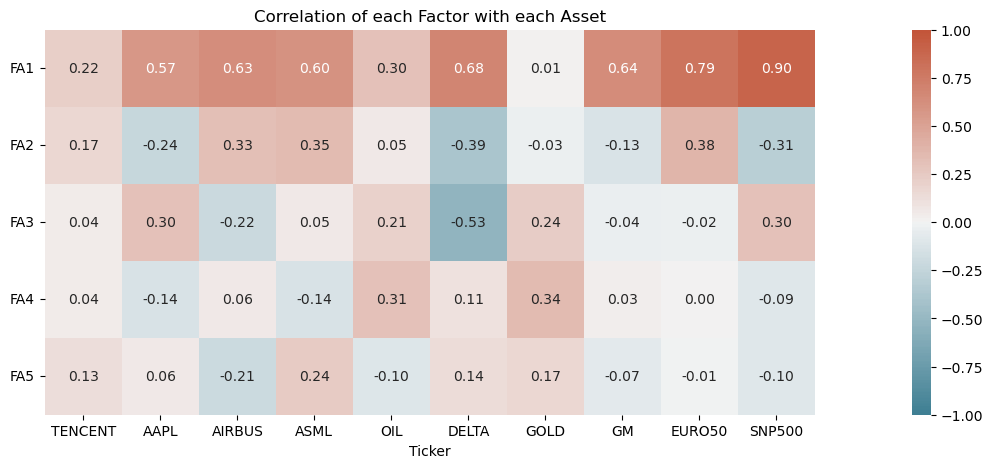

In [113]:
plt.figure(figsize=(25,5))
plt.title("Correlation of each Factor with each Asset")

# plot the heatmap for correlation matrix
ax = sns.heatmap(df_loadings_fa.T, 
                 vmin=-1, vmax=1, center=0,
                 cmap=sns.diverging_palette(220, 20, n=200),
                 square=True, annot=True, fmt='.2f')

ax.set_yticklabels(
    ax.get_yticklabels(),
    rotation=0)

### Adding Orthogonal Rotation

In [115]:
fa = FactorAnalyzer(n, rotation='varimax')
fa.fit(returns)

FactorAnalyzer(n_factors=5, rotation='varimax', rotation_kwargs={})

In [116]:
fa_loadings = fa.loadings_
fa_loadings_column = [f'FA{i}' for i in range(1, n + 1)]
df_loadings_fa = pd.DataFrame(fa_loadings, columns=fa_loadings_column, index=returns.columns)

[Text(0, 0.5, 'FA1'),
 Text(0, 1.5, 'FA2'),
 Text(0, 2.5, 'FA3'),
 Text(0, 3.5, 'FA4'),
 Text(0, 4.5, 'FA5')]

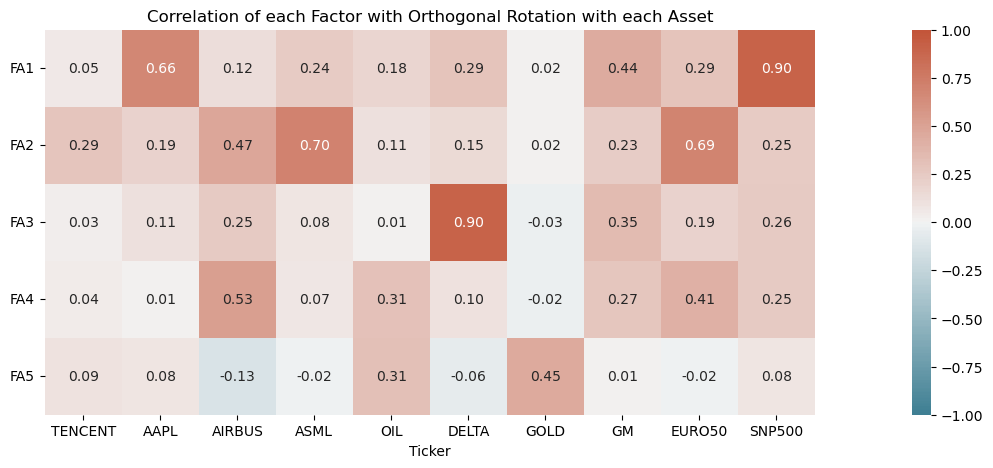

In [117]:
plt.figure(figsize=(25,5))
plt.title("Correlation of each Factor with Orthogonal Rotation with each Asset")

# plot the heatmap for correlation matrix
ax = sns.heatmap(df_loadings_fa.T, 
                 vmin=-1, vmax=1, center=0,
                 cmap=sns.diverging_palette(220, 20, n=200),
                 square=True, annot=True, fmt='.2f')

ax.set_yticklabels(
    ax.get_yticklabels(),
    rotation=0)

## Adding Oblique Rotation

In [119]:
fa = FactorAnalyzer(n, rotation='oblimin')
fa.fit(returns)

FactorAnalyzer(n_factors=5, rotation='oblimin', rotation_kwargs={})

In [120]:
fa_loadings = fa.loadings_
fa_loadings_column = [f'FA{i}' for i in range(1, n + 1)]
df_loadings_fa = pd.DataFrame(fa_loadings, columns=fa_loadings_column, index=returns.columns)

[Text(0, 0.5, 'FA1'),
 Text(0, 1.5, 'FA2'),
 Text(0, 2.5, 'FA3'),
 Text(0, 3.5, 'FA4'),
 Text(0, 4.5, 'FA5')]

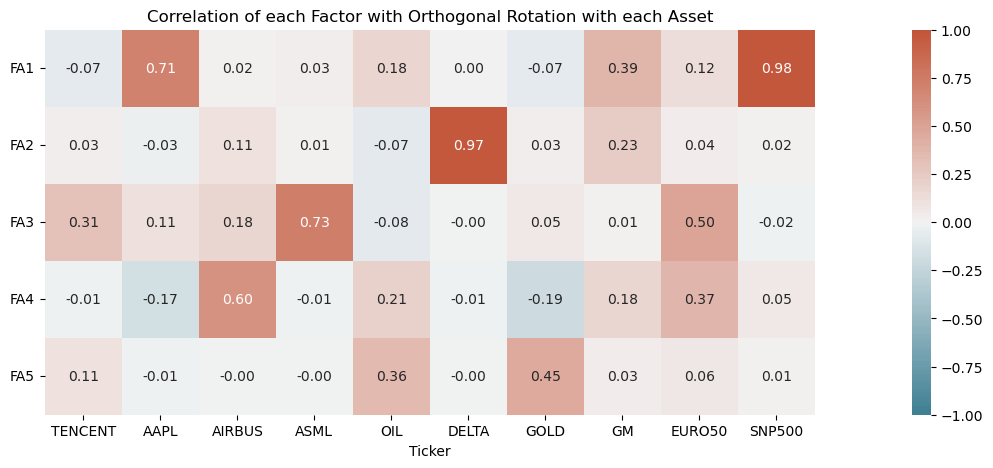

In [121]:
plt.figure(figsize=(25,5))
plt.title("Correlation of each Factor with Orthogonal Rotation with each Asset")

# plot the heatmap for correlation matrix
ax = sns.heatmap(df_loadings_fa.T, 
                 vmin=-1, vmax=1, center=0,
                 cmap=sns.diverging_palette(220, 20, n=200),
                 square=True, annot=True, fmt='.2f')

ax.set_yticklabels(
    ax.get_yticklabels(),
    rotation=0)